In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os

print("Student Roll No: 24BAD044")
print("TensorFlow Version:", tf.__version__)

Student Roll No: 24BAD044
TensorFlow Version: 2.20.0


In [2]:
!wget -q https://www.kaggle.com/api/v1/datasets/download/tongpython/cat-and-dog -O /content/cat-and-dog.zip
!unzip -q /content/cat-and-dog.zip -d /content/cat-and-dog

In [3]:
import os

BASE_PATH = "/content/cat-and-dog"

for root, dirs, files in os.walk(BASE_PATH):
    if files:
        print(root, "->", len(files), "files")

/content/cat-and-dog/training_set/training_set/dogs -> 4006 files
/content/cat-and-dog/training_set/training_set/cats -> 4001 files
/content/cat-and-dog/test_set/test_set/dogs -> 1013 files
/content/cat-and-dog/test_set/test_set/cats -> 1012 files


In [5]:
import tensorflow as tf
import os

BASE_PATH = "/content/cat-and-dog"

train_dir = os.path.join(BASE_PATH, "training_set/training_set")
test_dir = os.path.join(BASE_PATH, "test_set/test_set")

BATCH_SIZE = 32
IMG_SIZE = (224, 224)

train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE
)

test_full_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE
)

test_batches = tf.data.experimental.cardinality(test_full_dataset)

test_dataset = test_full_dataset.take(test_batches // 2)
val_dataset = test_full_dataset.skip(test_batches // 2)

print("Training batches:", tf.data.experimental.cardinality(train_dataset))
print("Validation batches:", tf.data.experimental.cardinality(val_dataset))
print("Test batches:", tf.data.experimental.cardinality(test_dataset))
print("Classes:", train_dataset.class_names)

Found 8005 files belonging to 2 classes.
Found 2023 files belonging to 2 classes.
Training batches: tf.Tensor(251, shape=(), dtype=int64)
Validation batches: tf.Tensor(32, shape=(), dtype=int64)
Test batches: tf.Tensor(32, shape=(), dtype=int64)
Classes: ['cats', 'dogs']


In [6]:
import tensorflow as tf

print("Student Roll No: 24BAD044")
print("Loading ResNet-50...")

preprocess_input = tf.keras.applications.resnet50.preprocess_input

base_model = tf.keras.applications.ResNet50(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("ResNet-50 loaded successfully!")

Student Roll No: 24BAD044
Loading ResNet-50...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
ResNet-50 loaded successfully!


In [8]:
inputs = tf.keras.Input(shape=(224, 224, 3))

x = preprocess_input(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │      2,049 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [9]:
print("Training the Transfer Learning Model...")

history = model.fit(
    train_dataset,
    epochs=5,
    validation_data=val_dataset
)

Training the Transfer Learning Model...
Epoch 1/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 1655s 7s/step - accuracy: 0.9686 - loss: 0.0873 - val_accuracy: 0.9860 - val_loss: 0.0400
Epoch 2/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 1706s 7s/step - accuracy: 0.9881 - loss: 0.0330 - val_accuracy: 0.9920 - val_loss: 0.0287
Epoch 3/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 1701s 7s/step - accuracy: 0.9909 - loss: 0.0249 - val_accuracy: 0.9880 - val_loss: 0.0315
Epoch 4/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 1594s 6s/step - accuracy: 0.9923 - loss: 0.0217 - val_accuracy: 0.9920 - val_loss: 0.0281
Epoch 5/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 1688s 7s/step - accuracy: 0.9939 - loss: 0.0173 - val_accuracy: 0.9900 - val_loss: 0.0414


In [10]:
print("Evaluating on Test Set...")

loss, accuracy = model.evaluate(test_dataset)

print("Test Accuracy:", accuracy)
print("Test Loss:", loss)
print("Jayaraksha 24BAD044")

Evaluating on Test Set...
32/32 ━━━━━━━━━━━━━━━━━━━━ 183s 6s/step - accuracy: 0.9863 - loss: 0.0405
Test Accuracy: 0.986328125
Test Loss: 0.04051603749394417
Jayaraksha 24BAD044


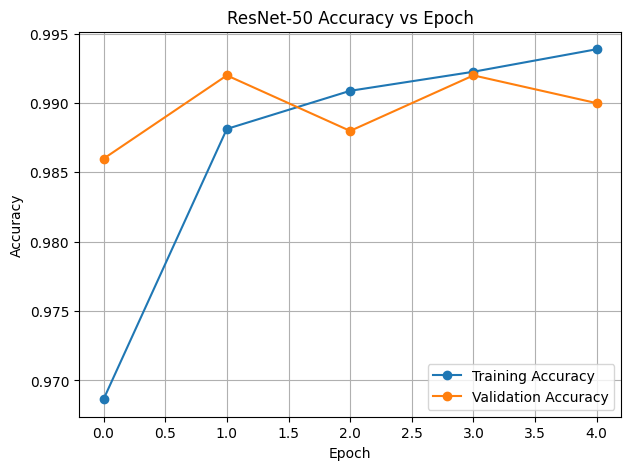

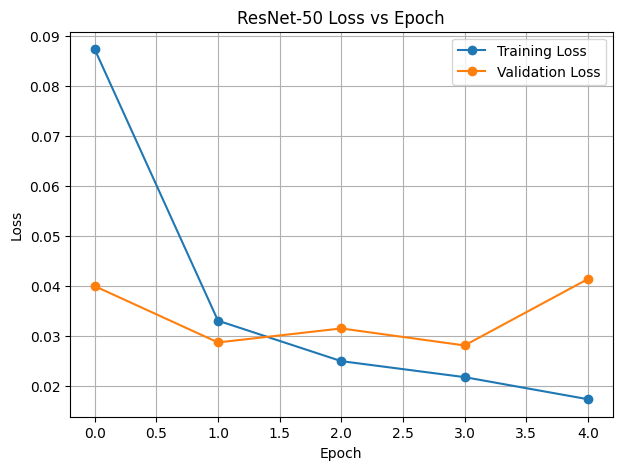

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("ResNet-50 Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7,5))
plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")
plt.title("ResNet-50 Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
!pip -q install transformers

In [13]:
from transformers import pipeline
from PIL import Image
import numpy as np

print("Loading Hugging Face ViT Model...")

hf_classifier = pipeline(
    "image-classification",
    model="google/vit-base-patch16-224"
)

print("Hugging Face model loaded successfully!")

Loading Hugging Face ViT Model...


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Hugging Face model loaded successfully!


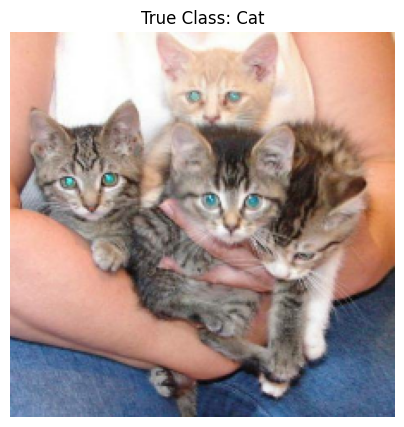

Model Predictions Comparison
--------------------------------
True Class: Cat
ResNet-50 Prediction: Cat
Probability of Dog: 0.0

Hugging Face ViT Top-3 Predictions:
tabby, tabby cat : 0.5915
Egyptian cat : 0.2398
tiger cat : 0.074

Student Roll No: 24BAD044


In [14]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

for images, labels in test_dataset.take(1):
    sample_image = images[0].numpy().astype("uint8")
    sample_label = labels[0].numpy()

pil_image = Image.fromarray(sample_image)

hf_predictions = hf_classifier(pil_image)

resnet_prob = model.predict(
    np.expand_dims(sample_image, axis=0),
    verbose=0
)[0][0]

resnet_pred_class = "Dog" if resnet_prob > 0.5 else "Cat"
true_class = "Dog" if sample_label == 1 else "Cat"

plt.figure(figsize=(5,5))
plt.imshow(sample_image)
plt.title("True Class: " + true_class)
plt.axis("off")
plt.show()

print("Model Predictions Comparison")
print("--------------------------------")
print("True Class:", true_class)
print("ResNet-50 Prediction:", resnet_pred_class)
print("Probability of Dog:", round(float(resnet_prob), 4))

print("\nHugging Face ViT Top-3 Predictions:")
for pred in hf_predictions[:3]:
    print(pred["label"], ":", round(pred["score"], 4))

print("\nStudent Roll No: 24BAD044")